# Analyse de l'inventaire de fin de mois (`inventory_month_end`) : exploration, patterns et anomalies

**Contexte.** Ce notebook applique à la table `inventory_month_end.csv` (stocks de fin de mois par site et par catégorie d'article : stock d'ouverture, quantités reçues et sorties, consommation interne et pertes documentées, stock de clôture, statut de l'inventaire) **la même démarche que les notebooks des expéditions et des achats**. L'objectif est de comprendre la structure des données, puis de repérer des **comportements inhabituels** : combinaisons rares mais cohérentes (*patterns*) et lignes statistiquement atypiques (*anomalies*).

**Particularité de cette table.** Le stock de clôture devrait être égal au stock d'ouverture, plus les entrées, moins les sorties, la consommation interne et les pertes documentées. On construit donc dès le nettoyage une variable clé, l'**écart de stock** (stock réel − stock attendu), qui mesure ce qui **manque ou ce qui sur-abonde sans explication** dans les mouvements enregistrés.



---
## 0. Configuration

### 0.1 Imports et modules utilitaires

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

project_root = next(
	(path for path in [Path.cwd(), *Path.cwd().parents]
	 if (path / "utils").is_dir()),
	Path.cwd(),
)
if str(project_root) not in sys.path:
	sys.path.insert(0, str(project_root))

from utils.clean_csv import clean_csv
from utils.variable_analysis import analyser_variables, tracer_histogrammes
from utils.correlation_matrices import tracer_matrices
from utils.pattern_detection import lire_csv, enrichir, detecter_patterns, profiler_groupe, masque_itemset
from utils.anomaly_detection import detecter_anomalies


**Rapport.** Mêmes modules `utils` que pour les autres tables : `clean_csv` (nettoyage), `variable_analysis` (histogrammes et statistiques), `correlation_matrices` (Spearman / V de Cramér), `pattern_detection` (itemsets fréquents) et `anomaly_detection` (IQR, clustering, ABOD). Le dossier racine du projet est ajouté automatiquement au `sys.path`.

---
## 1. Chargement, nettoyage et variables dérivées

### 1.1 Lecture et nettoyage du fichier


Deux adaptations, justifiées par l'inspection du fichier brut :
- **Nombres écrits comme du texte** : certaines colonnes de stock contiennent des valeurs avec leur unité (`"14.55 sealed_lot"`, `"270.62 case"`) ou une virgule décimale (`"1,04"`). On extrait le nombre avant le nettoyage, sinon ces valeurs deviendraient manquantes.
- **`outlier_method=None`** : on désactive la transformation automatique des « valeurs aberrantes » en valeurs manquantes (voir le contrôle du 1.2).

In [2]:
# 1) Colonnes numériques lues comme du texte (valeurs avec unité ou virgule décimale) : on garde le nombre
brut = pd.read_csv("../data/logistics/inventory_month_end.csv")
cols_stock = ["opening_stock", "received_quantity", "outgoing_quantity",
              "documented_internal_use", "documented_waste", "closing_stock"]
for c in cols_stock:
    brut[c] = brut[c].astype(str).str.extract(r"^\s*(-?[\d.,]+)")[0]

# 2) Nettoyage générique. outlier_method=None : on NE transforme PAS les valeurs extrêmes en valeurs manquantes
inv, rapport = clean_csv(brut, outlier_method=None)

Avant nettoyage : (502, 11)
Après suppression des doublons : (500, 11)
Dates normalisées : {'reporting_month': 'datetime64[ns]'}
inventory_status : 5 -> 3 modalités distinctes

Forme finale : (500, 11)
Valeurs manquantes après traitement :
Aucune


In [3]:
# Vérification : que ferait le nettoyage avec son réglage par défaut (IQR global, facteur 3) ?
inv_defaut, _ = clean_csv(brut, verbose=False)
perdus = inv_defaut[cols_stock].isna().sum()
print(f"Valeurs transformées en valeurs manquantes par défaut : {int(perdus.sum())}")
print(perdus.to_string())
lignes = inv_defaut[cols_stock].isna().any(axis=1)
print(f"Lignes touchées : {int(lignes.sum())} sur {len(inv_defaut)}")
print(inv_defaut[lignes].item_category.value_counts().to_string())

Valeurs transformées en valeurs manquantes par défaut : 82
opening_stock              15
received_quantity          15
outgoing_quantity           8
documented_internal_use    10
documented_waste           18
closing_stock              16
Lignes touchées : 40 sur 500
item_category
medical_consumables     20
protective_equipment    13
monitoring_equipment     4
agricultural_product     3


### Rapport d'analyse — nettoyage

**Résultats**
- La table passe de **502 à 500 lignes** (11 colonnes) : 2 doublons exacts sont supprimés (une ligne de `FCL-1019` en mai 2021 et une de `FCL-1020` en août 2019).
- `inventory_status` passe de **5 à 3 modalités** (`closed`, `provisional`, `revised`) : les variantes `CLOSED` et `PROVISIONAL` étaient comptées à part. `reporting_month` est convertie en date.
- 16 valeurs numériques étaient écrites sous forme de texte (calcul complémentaire) : 8 avec une unité (4 en stock d'ouverture, 4 en stock de clôture) et 8 avec une virgule décimale (3 entrées, 3 sorties, 2 pertes). Elles sont récupérées par le prétraitement ; le contrôle de continuité du 1.3 (0 rupture) confirme que les conversions sont correctes.
- Le contrôle final indique *« Aucune »* valeur manquante.



### 1.3 Variables dérivées : l'écart de stock



In [4]:
# Écart de stock = stock final réel - stock final attendu par le bilan comptable des mouvements
inv = inv.sort_values(["facility_code", "item_category", "reporting_month"]).reset_index(drop=True)
inv["ecart_stock"] = inv.closing_stock - (inv.opening_stock + inv.received_quantity
                     - inv.outgoing_quantity - inv.documented_internal_use - inv.documented_waste)
inv["ecart_classe"] = pd.cut(inv.ecart_stock, [-np.inf, -5, 5, np.inf],
                             labels=["perte_forte (< -5)", "equilibre (-5 a 5)", "gain_fort (> 5)"]).astype(str)

# Contrôle de continuité : le stock d'ouverture doit être égal au stock de clôture de la période précédente
serie = inv.groupby(["facility_code", "item_category"])
rupture = (inv.opening_stock - serie.closing_stock.shift()).abs() > 0.011
print(f"Séries (site x catégorie) : {serie.ngroups} | mois par série : {int(serie.size().min())} à {int(serie.size().max())}")
print(f"Ruptures de continuité ouverture / clôture précédente : {int(rupture.sum())} sur {int(serie.closing_stock.shift().notna().sum())}")
print("\nÉcart de stock (hors 0 attendu) :")
print(inv.ecart_stock.describe().round(2).to_string())
print("\nÉcart moyen par statut :")
print(inv.groupby("inventory_status").ecart_stock.agg(["count", "mean", "min", "max"]).round(2).to_string())

Séries (site x catégorie) : 25 | mois par série : 20 à 20
Ruptures de continuité ouverture / clôture précédente : 0 sur 475

Écart de stock (hors 0 attendu) :
count    500.00
mean      -0.02
std        4.47
min      -21.80
25%       -1.21
50%        0.18
75%        1.66
max       44.37

Écart moyen par statut :
                  count  mean    min    max
inventory_status                           
closed              444  0.37 -21.80  44.37
provisional          38 -0.37  -5.13   7.69
revised              18 -9.01 -17.76   0.31


### Rapport d'analyse — variables dérivées

**Résultats**
- **Une structure de panel parfaitement équilibrée** : 25 séries (5 sites × 5 catégories) de **20 relevés chacune**, soit 500 lignes. Les 20 mois sont les mêmes pour toutes les séries (de février 2018 à juin 2025), mais ils ne sont **pas consécutifs** : l'intervalle entre deux relevés varie de 28 à 335 jours (calcul complémentaire).
- **Continuité parfaite** : 0 rupture sur 475 comparaisons, c'est-à-dire que le stock d'ouverture est toujours égal à la clôture du relevé précédent, même quand plusieurs mois séparent les deux. Les relevés sont donc enchaînés d'une période à l'autre.
- **Écart de stock** : moyenne −0,02, médiane 0,18, Q1-Q3 de −1,21 à 1,66, extrêmes de **−21,80 à +44,37**, asymétrie 2,02. Le bilan comptable est donc **presque** vérifié : 90,6 % des lignes sont à moins de 5 unités d'écart, mais **28 lignes (5,6 %) manquent de plus de 5 unités** et 19 (3,8 %) en ont plus que prévu.
- **Écart moyen par statut** : `closed` **+0,37** (444 lignes), `provisional` −0,37 (38 lignes) et `revised` **−9,01** (18 lignes, de −17,76 à +0,31).



### 1.4 Aperçu des données

In [5]:
inv.head(5)

,facility_code,reporting_month,item_category,opening_stock,received_quantity,outgoing_quantity,documented_internal_use,documented_waste,closing_stock,unit,inventory_status,ecart_stock,ecart_classe
0,FCL-1010,2018-02-01,agricultural_product,47.51,6.37,0.25,5.22,1.33,43.70,pallet,closed,-3.38,equilibre (-5 a 5)
1,FCL-1010,2018-03-01,agricultural_product,43.70,2.45,5.68,1.51,1.36,38.51,pallet,closed,0.91,equilibre (-5 a 5)
2,FCL-1010,2018-05-01,agricultural_product,38.51,0.00,0.00,1.75,1.87,37.11,pallet,closed,2.22,equilibre (-5 a 5)
3,FCL-1010,2019-01-01,agricultural_product,37.11,0.00,0.00,2.04,0.05,36.01,pallet,closed,0.99,equilibre (-5 a 5)
4,FCL-1010,2019-08-01,agricultural_product,36.01,0.00,0.00,1.04,0.04,34.42,pallet,closed,-0.51,equilibre (-5 a 5)


**Rapport.** Les 13 colonnes se regroupent en : **identification** (`facility_code`, `item_category`, `reporting_month`), **mouvements** (`opening_stock`, `received_quantity`, `outgoing_quantity`, `documented_internal_use`, `documented_waste`), **résultat** (`closing_stock`, `unit`, `inventory_status`) et les deux **variables dérivées** (`ecart_stock`, `ecart_classe`). La première ligne illustre le bilan : un stock d'ouverture de 47,51 plus 6,37 reçus, moins 0,25 sorti, 5,22 d'usage interne et 1,33 de perte, donne 47,08 attendus, alors que le stock de clôture enregistré est 43,70 : un écart de −3,38.

---
## 2. Analyse univariée

### 2.1 Histogrammes et statistiques descriptives



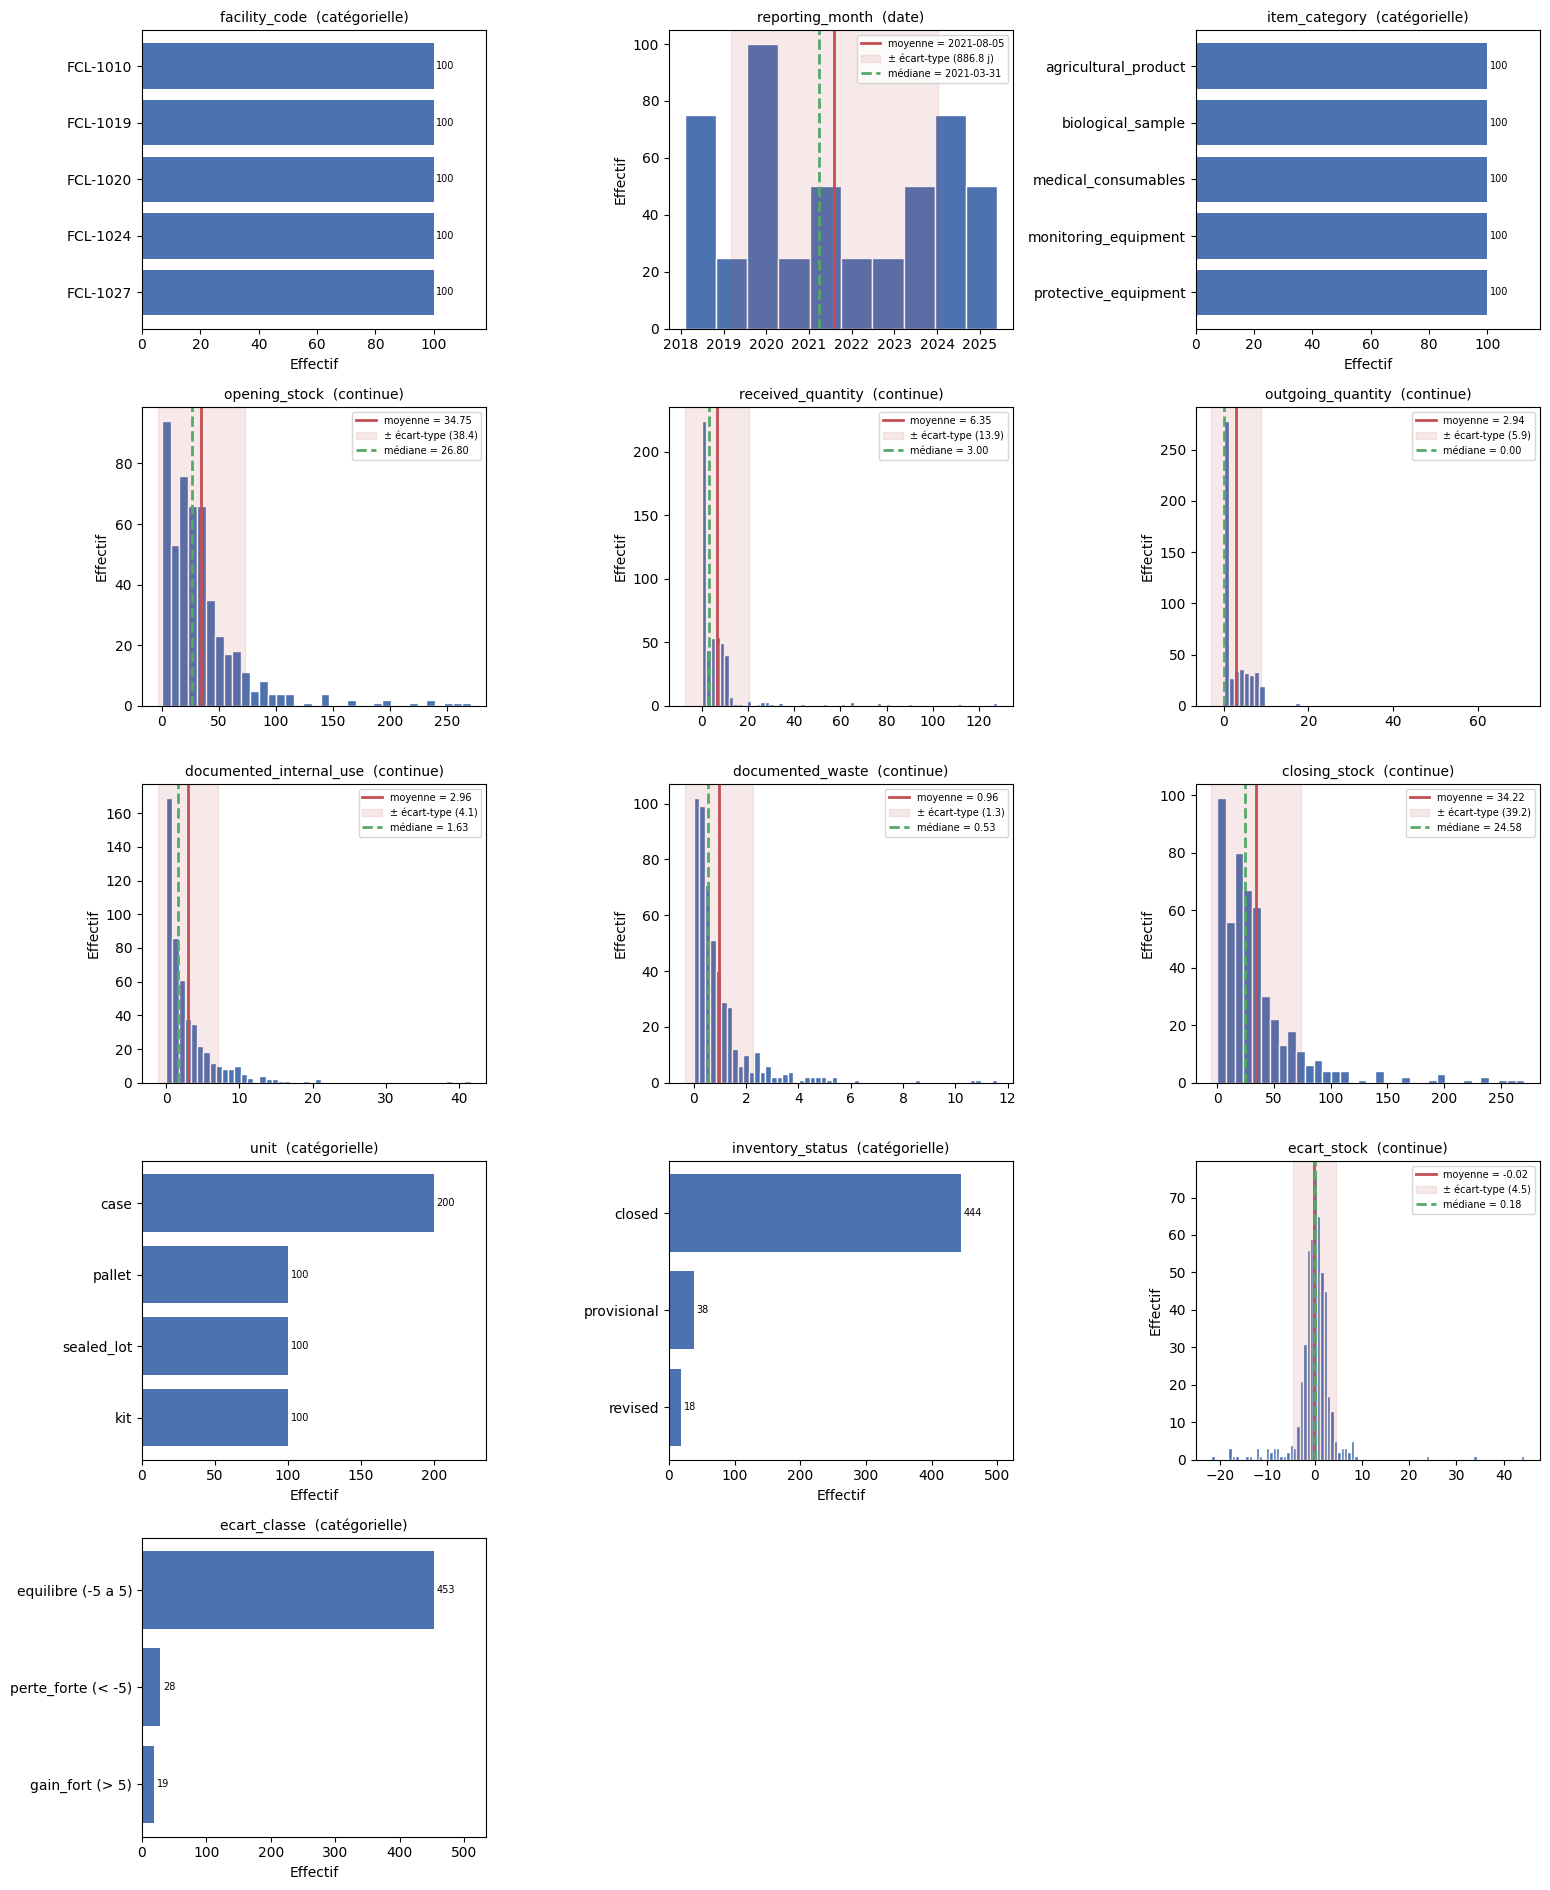


=== facility_code  [catégorielle] ===
  Effectif : 500  (manquants : 0, modalités : 5)
  Mode : FCL-1010 (20.0 %)
               effectif     %
facility_code                
FCL-1010            100  20.0
FCL-1019            100  20.0
FCL-1020            100  20.0
FCL-1024            100  20.0
FCL-1027            100  20.0


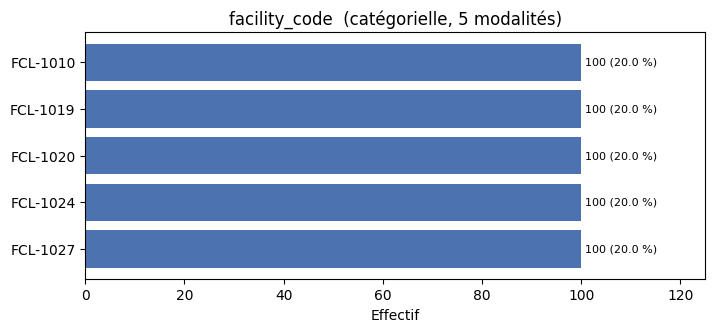


=== reporting_month  [date] ===
  Effectif : 500  (manquants : 0, valeurs distinctes : 20)
  Moyenne ± écart-type : 2021-08-05 ± 886.8 jours
  Médiane [min ; Q1 - Q3 ; max] : 2021-03-31 [2018-02-01 ; 2019-08-24 - 2023-12-01 ; 2025-06-01]
  Asymétrie : 0.10


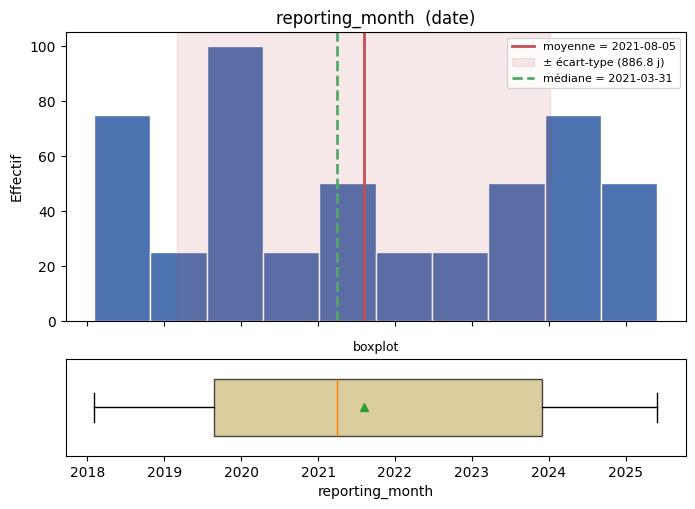


=== item_category  [catégorielle] ===
  Effectif : 500  (manquants : 0, modalités : 5)
  Mode : agricultural_product (20.0 %)
                      effectif     %
item_category                       
agricultural_product       100  20.0
biological_sample          100  20.0
medical_consumables        100  20.0
monitoring_equipment       100  20.0
protective_equipment       100  20.0


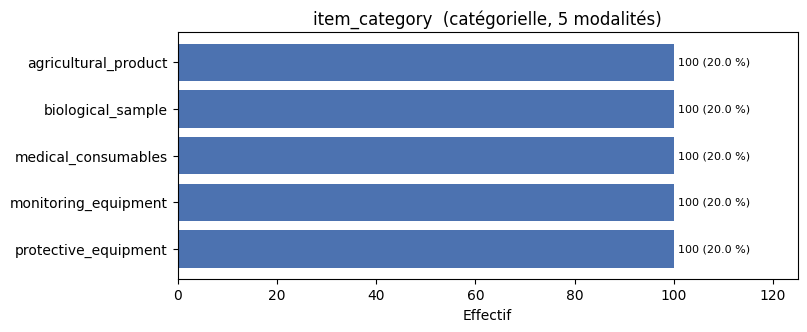


=== opening_stock  [continue] ===
  Effectif : 500  (manquants : 0, valeurs distinctes : 438)
  Moyenne ± écart-type : 34.753 ± 38.376
  Médiane [min ; Q1 - Q3 ; max] : 26.795 [0.000 ; 12.240 - 43.520 ; 270.620]
  Asymétrie : 2.95


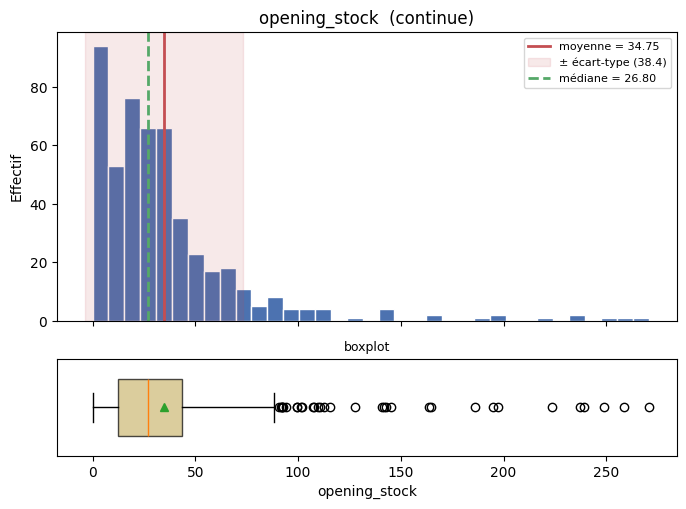


=== received_quantity  [continue] ===
  Effectif : 500  (manquants : 0, valeurs distinctes : 256)
  Moyenne ± écart-type : 6.349 ± 13.895
  Médiane [min ; Q1 - Q3 ; max] : 3.000 [0.000 ; 0.000 - 7.763 ; 128.000]
  Asymétrie : 5.55


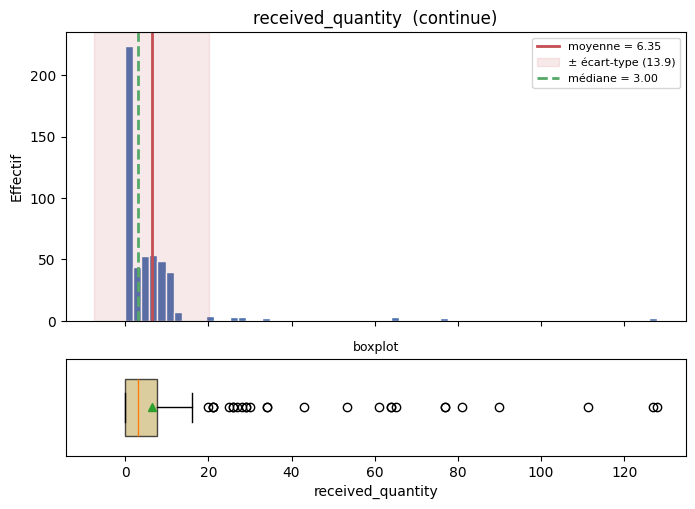


=== outgoing_quantity  [continue] ===
  Effectif : 500  (manquants : 0, valeurs distinctes : 216)
  Moyenne ± écart-type : 2.941 ± 5.853
  Médiane [min ; Q1 - Q3 ; max] : 0.000 [0.000 ; 0.000 - 4.790 ; 71.000]
  Asymétrie : 6.28


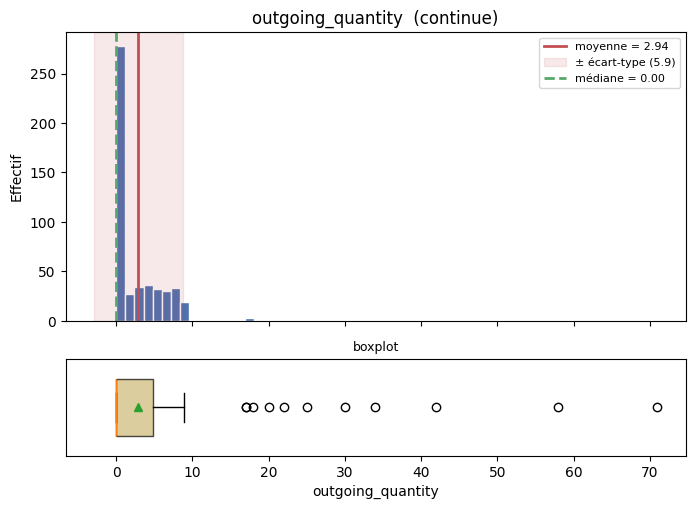


=== documented_internal_use  [continue] ===
  Effectif : 500  (manquants : 0, valeurs distinctes : 329)
  Moyenne ± écart-type : 2.958 ± 4.125
  Médiane [min ; Q1 - Q3 ; max] : 1.630 [0.000 ; 0.508 - 3.882 ; 41.590]
  Asymétrie : 4.08


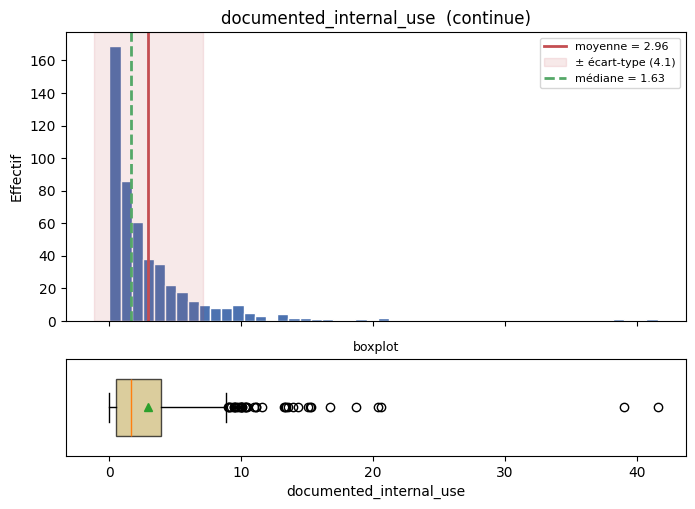


=== documented_waste  [continue] ===
  Effectif : 500  (manquants : 0, valeurs distinctes : 206)
  Moyenne ± écart-type : 0.960 ± 1.308
  Médiane [min ; Q1 - Q3 ; max] : 0.530 [0.000 ; 0.260 - 1.110 ; 11.610]
  Asymétrie : 4.08


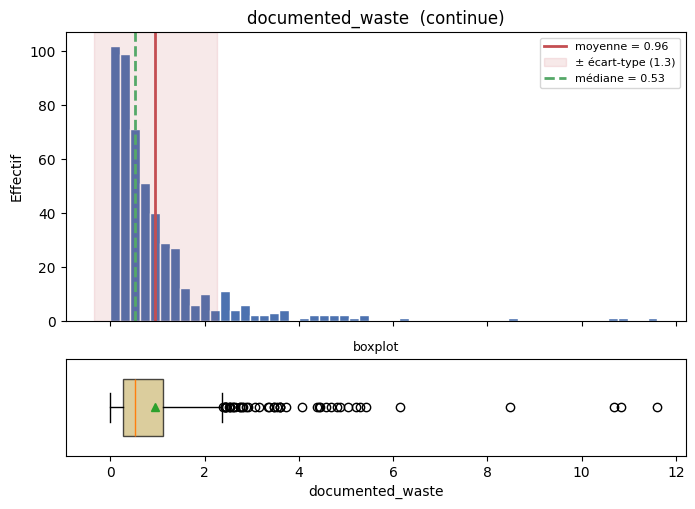


=== closing_stock  [continue] ===
  Effectif : 500  (manquants : 0, valeurs distinctes : 433)
  Moyenne ± écart-type : 34.220 ± 39.239
  Médiane [min ; Q1 - Q3 ; max] : 24.580 [0.000 ; 10.745 - 42.170 ; 270.620]
  Asymétrie : 2.93


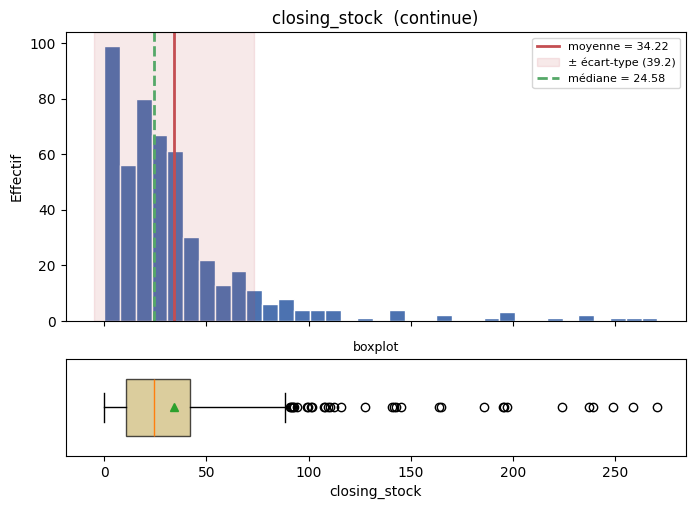


=== unit  [catégorielle] ===
  Effectif : 500  (manquants : 0, modalités : 4)
  Mode : case (40.0 %)
            effectif     %
unit                      
case             200  40.0
pallet           100  20.0
sealed_lot       100  20.0
kit              100  20.0


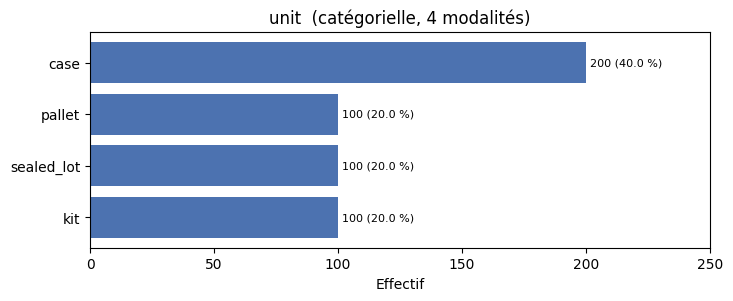


=== inventory_status  [catégorielle] ===
  Effectif : 500  (manquants : 0, modalités : 3)
  Mode : closed (88.8 %)
                  effectif     %
inventory_status                
closed                 444  88.8
provisional             38   7.6
revised                 18   3.6


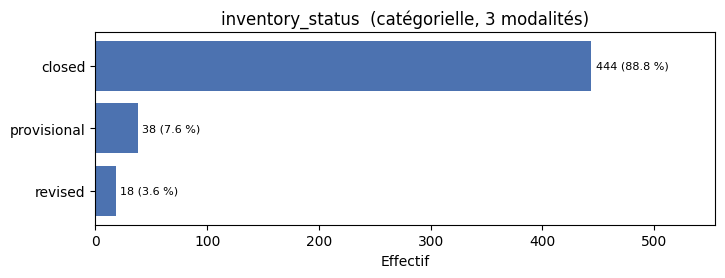


=== ecart_stock  [continue] ===
  Effectif : 500  (manquants : 0, valeurs distinctes : 463)
  Moyenne ± écart-type : -0.024 ± 4.473
  Médiane [min ; Q1 - Q3 ; max] : 0.180 [-21.800 ; -1.207 - 1.662 ; 44.370]
  Asymétrie : 2.02


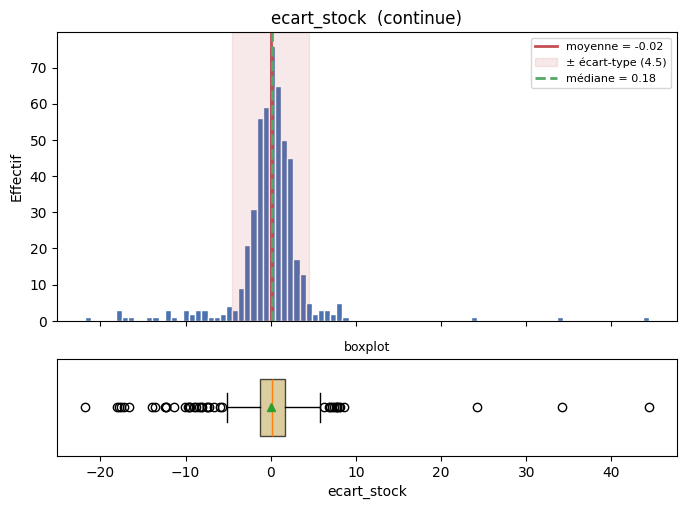


=== ecart_classe  [catégorielle] ===
  Effectif : 500  (manquants : 0, modalités : 3)
  Mode : equilibre (-5 a 5) (90.6 %)
                    effectif     %
ecart_classe                      
equilibre (-5 a 5)       453  90.6
perte_forte (< -5)        28   5.6
gain_fort (> 5)           19   3.8


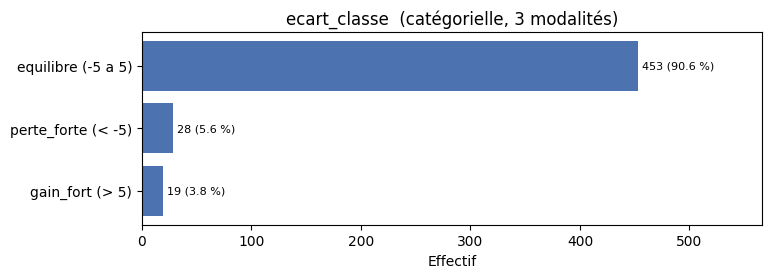

In [6]:
tracer_histogrammes(inv)
resume = analyser_variables(inv)

### Rapport d'analyse — analyse univariée

**1. Variables d'identification : un plan d'observation équilibré**
- 5 sites (`FCL-1010`, `1019`, `1020`, `1024`, `1027`) et 5 catégories ont **exactement 100 lignes chacun (20 %)**. Les unités sont déterminées par la catégorie : `case` 200 lignes (40 % : consommables médicaux et équipements de protection), `pallet` (produits agricoles), `sealed_lot` (échantillons biologiques) et `kit` (équipements de suivi) à 100 chacun.
- 20 dates distinctes, du 1ᵉʳ février 2018 au 1ᵉʳ juin 2025 (médiane au 31 mars 2021).
- Cette régularité traduit un **échantillon construit** (même nombre de lignes par site et par catégorie) : la fréquence d'un site ou d'une catégorie n'apporte aucune information sur son activité.
- Statut : `closed` **88,8 %** (444), `provisional` 7,6 % (38) et `revised` 3,6 % (18).

**2. Stocks et mouvements : distributions très étalées, avec beaucoup de zéros**
- **Stock d'ouverture** : moyenne 34,75 ± 38,38, médiane 26,8, maximum **270,62**, asymétrie 2,95. **Stock de clôture** : moyenne 34,22, médiane 24,6, maximum 270,62, asymétrie 2,93. La clôture est légèrement inférieure à l'ouverture.
- **Entrées** : médiane 3,0, moyenne 6,35 ± 13,90, maximum **128** (asymétrie 5,55) ; 199 lignes (40 %) n'ont aucune entrée.
- **Sorties** : **médiane 0**, moyenne 2,94 ± 5,85, maximum **71** (asymétrie 6,28) ; 251 lignes (50 %) n'ont aucune sortie.
- **Consommation interne** : médiane 1,63, moyenne 2,96, maximum 41,59 (asymétrie 4,08). **Pertes documentées** : médiane 0,53, moyenne 0,96, maximum 11,61 (asymétrie 4,08).
- 52 lignes ont un stock d'ouverture nul et 56 un stock de clôture nul, soit environ 11 % de ruptures (calcul complémentaire).

**3. Écart de stock**
- 90,6 % des lignes sont à l'équilibre (453), **5,6 % présentent une perte forte** (28) et 3,8 % un gain fort (19).



---
## 3. Associations entre variables

### 3.1 Matrices de corrélation et V de Cramér



Variables utilisées (8) : ['reporting_month (date -> jours)', 'opening_stock (numérique)', 'received_quantity (numérique)', 'outgoing_quantity (numérique)', 'documented_internal_use (numérique)', 'documented_waste (numérique)', 'closing_stock (numérique)', 'ecart_stock (numérique)']
Variables exclues : ['facility_code (catégorielle)', 'item_category (catégorielle)', 'unit (catégorielle)', 'inventory_status (catégorielle)', 'ecart_classe (catégorielle)']


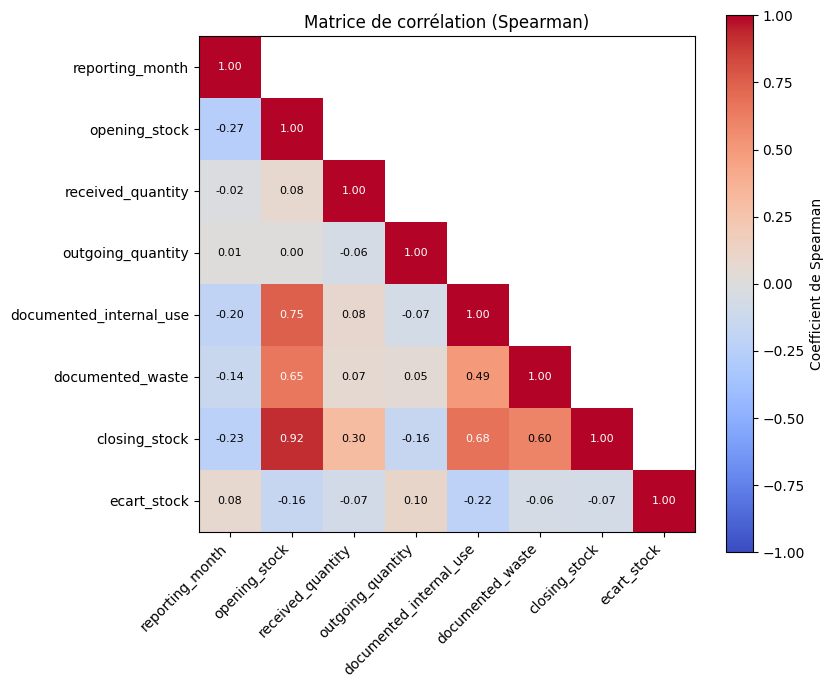


Paires avec |spearman| >= 0.7 :
             variable_1    variable_2   valeur
          closing_stock opening_stock 0.918625
documented_internal_use opening_stock 0.747110
Variables catégorielles utilisées (5) : ['facility_code', 'item_category', 'unit', 'inventory_status', 'ecart_classe']
Variables exclues : ['reporting_month (date)', 'opening_stock (numérique)', 'received_quantity (numérique)', 'outgoing_quantity (numérique)', 'documented_internal_use (numérique)', 'documented_waste (numérique)', 'closing_stock (numérique)', 'ecart_stock (numérique)']


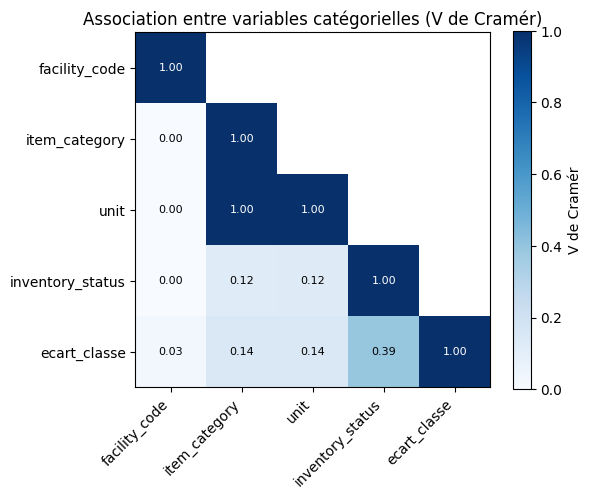


Paires avec |V de Cramér| >= 0.5 :
variable_1    variable_2   valeur
      unit item_category 0.998991


In [7]:
resultats = tracer_matrices(inv)

### Rapport d'analyse — associations

**Interprétation**
- Le **stock est très persistant** (0,92 entre ouverture et clôture) et les consommations **proportionnelles au stock** : plus le stock est élevé, plus l'usage interne et les pertes documentées sont élevés.
- En revanche, les **entrées et les sorties ne suivent pas le niveau de stock** : il n'y a aucune logique de réapprovisionnement visible (une entrée n'est pas plus probable quand le stock est bas). Ces flux sont pilotés par des événements extérieurs (commandes, expéditions), ce que le recoupement de l'étape 4 confirme.
- L'écart de stock **n'est pas expliqué par les variables numériques** : c'est bien une perte « inexpliquée » au sens strict.
- **`facility_code` est indépendant de la catégorie (V = 0)** : chaque site a toutes les catégories, ce qui confirme le plan équilibré. `unit` est redondante avec `item_category`.
- **Le statut `revised` est le seul à se relier à l'écart (0,39)** : cela confirme l'observation de l'étape 1.3 et se précise à l'étape 5.

---
## 4. Recherche de patterns : itemsets fréquents

### 4.1 Enrichissement et extraction des itemsets


Le tableau est enrichi avec la région et les capacités de stockage du site (`erp_facilities`) et l'année. Sont exclues de la recherche : `unit` (redondante avec la catégorie), `reporting_month` (remplacée par l'année) et `ecart_stock` (remplacée par sa version en classes).

In [8]:
fa = lire_csv("../data/logistics/erp_facilities.csv")

inv_p = enrichir(inv, fa, cle="facility_code", cle_autre="facility_code",
                 colonnes=["region", "storage_capabilities"], prefixe="site_")
inv_p["annee"] = inv_p.reporting_month.dt.year.astype(str)

# unit est déterminée par item_category (V = 1) ; reporting_month est remplacée par l'année ;
# ecart_stock est remplacé par sa version en classes (ecart_classe)
res = detecter_patterns(inv_p, min_support=0.02, exclure=["unit", "reporting_month", "ecart_stock"])
F = res["itemsets"]

Transactions : 500 | colonnes utilisées : 13 | items distincts : 47

min_support = 0.020 (support absolu >= 10) -> 46031 itemsets fréquents, dont 13255 fermés
Répartition par taille : {1: 47, 2: 828, 3: 4258, 4: 10026, 5: 13068, 6: 10372, 7: 5288, 8: 1757, 9: 354, 10: 33}

--- Itemsets les plus FRÉQUENTS (taille >= 2) : décrivent surtout la majorité ---
                                                                                    itemset  support_abs  support_rel  lift
                                  ecart_classe=equilibre (-5 a 5) ∧ inventory_status=closed          412        0.824 1.024
                           ecart_classe=equilibre (-5 a 5) ∧ outgoing_quantity=[0 .. 3.167]          309        0.618 1.024
                           ecart_classe=equilibre (-5 a 5) ∧ received_quantity=[0 .. 6.293]          304        0.608 1.008
                                   inventory_status=closed ∧ received_quantity=[0 .. 6.293]          295        0.590 0.998
                        

### 4.2 Profil du groupe le plus surprenant



In [9]:
# Profil du groupe décrit par l'itemset le plus surprenant (et non le plus fréquent)
S = res["surprenants"]
itemset = frozenset(S.itemset.iloc[0])
groupe = masque_itemset(res["transactions"], itemset, inv_p.index)
print("Itemset analysé :", " ∧ ".join(sorted(itemset)))
print("Effectif du groupe :", int(groupe.sum()), "lignes sur", len(inv_p))
profil = profiler_groupe(inv_p, groupe)
print(profil[profil.part_groupe >= 0.95][["colonne", "valeur_dominante", "part_groupe", "part_ensemble"]].to_string())

Itemset analysé : closing_stock=[34.42 .. 270.6] ∧ documented_internal_use=[2.807 .. 41.59] ∧ documented_waste=[0.88 .. 11.61] ∧ facility_code=fcl-1010 ∧ inventory_status=closed ∧ item_category=medical_consumables ∧ opening_stock=[35.99 .. 270.6] ∧ received_quantity=[6.293 .. 128] ∧ site_region=valenne central district ∧ site_storage_capabilities=2-8c;controlled_access
Effectif du groupe : 10 lignes sur 500
                     colonne          valeur_dominante  part_groupe  part_ensemble
0              facility_code                  fcl-1010          1.0          0.200
1              item_category       medical_consumables          1.0          0.200
2  site_storage_capabilities    2-8c;controlled_access          1.0          0.200
3                       unit                      case          1.0          0.400
4                site_region  valenne central district          1.0          0.400
5           inventory_status                    closed          1.0          0.888


### Rapport d'analyse — patterns


**Interprétation et réserves**
- Ces itemsets décrivent surtout le **niveau d'échelle de chaque série** : les consommables médicaux de `FCL-1010` sont stockés en grande quantité, les échantillons biologiques de `FCL-1027` en très faible quantité. C'est une propriété de la série, pas un comportement inhabituel. Les lifts sont en outre **gonflés** par la redondance entre site, région et capacités (un site détermine ses deux attributs).
- **Les écarts de stock n'apparaissent pas** dans les itemsets les plus surprenants : les 28 pertes fortes (5,6 %) sont dispersées sur plusieurs séries, à un support par série trop faible pour émerger. Il faut donc chercher leur origine ailleurs : c'est l'objet du recoupement qui suit.

### 4.3 Recoupement avec les expéditions



In [10]:
# Recoupement avec les expéditions : les sorties et les entrées de stock correspondent-elles aux expéditions ?
sh, _ = clean_csv("../data/logistics/shipments.csv", verbose=False)
sh["mois_depart"] = pd.to_datetime(sh.dispatch_time, format="mixed").dt.to_period("M").dt.to_timestamp()
sh["mois_arrivee"] = pd.to_datetime(sh.arrival_time.replace("unknown", np.nan), format="mixed",
                                    errors="coerce").dt.to_period("M").dt.to_timestamp()
sh["wildlife"] = sh.declared_purpose.str.contains("wildlife")

cle = ["facility_code", "reporting_month", "item_category"]
sorties = (sh.groupby(["origin_facility_code", "mois_depart", "item_category"])
             .agg(exp_sortie=("declared_quantity", "sum"), wildlife_sortie=("wildlife", "any")).reset_index()
             .rename(columns={"origin_facility_code": cle[0], "mois_depart": cle[1]}))
entrees = (sh.dropna(subset=["mois_arrivee"]).groupby(["destination_facility_code", "mois_arrivee", "item_category"])
             .agg(exp_entree=("declared_quantity", "sum"), wildlife_entree=("wildlife", "any")).reset_index()
             .rename(columns={"destination_facility_code": cle[0], "mois_arrivee": cle[1]}))
m = inv.merge(sorties, on=cle, how="left").merge(entrees, on=cle, how="left")

# 1) Sorties de stock = quantités expédiées au départ du site ?
s = m[m.exp_sortie.notna()]
print(f"Lignes d'inventaire avec sortie > 0 : {int((m.outgoing_quantity > 0).sum())} | "
      f"avec une expédition au départ le même mois : {len(s)} | quantités identiques : {int((s.outgoing_quantity == s.exp_sortie).sum())}")
# 2) Entrées de stock = quantités expédiées à l'arrivée sur le site ?
e = m[m.exp_entree.notna()]
print(f"Lignes d'inventaire avec entrée > 0 : {int((m.received_quantity > 0).sum())} | "
      f"avec une expédition arrivée le même mois : {len(e)} | quantités identiques : {int((e.received_quantity == e.exp_entree).sum())}")

# 3) L'écart de stock selon qu'une expédition « wildlife » est liée à la ligne (départ ou arrivée)
m["lien_wildlife"] = m.wildlife_sortie.fillna(False).astype(bool) | m.wildlife_entree.fillna(False).astype(bool)
m["lien_expedition"] = m.exp_sortie.notna() | m.exp_entree.notna()
m["groupe"] = np.select([m.lien_wildlife, m.lien_expedition], ["lié à une expédition wildlife", "lié à une autre expédition"],
                        "aucune expédition ce mois")
print("\nÉcart de stock par groupe de lignes :")
print(m.groupby("groupe").ecart_stock.agg(n="count", moyenne="mean", mediane="median", minimum="min", maximum="max").round(2).to_string())
w = m[m.lien_wildlife]
print(f"\nLignes liées à une expédition wildlife : {len(w)} | écart négatif : {int((w.ecart_stock < 0).sum())} | "
      f"écart total : {w.ecart_stock.sum():.1f}")
print(w.groupby(["facility_code", "item_category"]).ecart_stock.agg(n="count", moyenne="mean").round(2).to_string())

# 4) Même série (échantillons biologiques), mois liés / non liés à une expédition wildlife
bio = m[(m.item_category == "biological_sample") & m.facility_code.isin(["FCL-1019", "FCL-1020", "FCL-1024"])]
print("\nÉchantillons biologiques : écart moyen selon le lien avec une expédition wildlife")
print(bio.groupby(["facility_code", "lien_wildlife"]).ecart_stock.agg(n="count", moyenne="mean").round(2).to_string())

Lignes d'inventaire avec sortie > 0 : 249 | avec une expédition au départ le même mois : 27 | quantités identiques : 27
Lignes d'inventaire avec entrée > 0 : 301 | avec une expédition arrivée le même mois : 36 | quantités identiques : 31

Écart de stock par groupe de lignes :
                                 n  moyenne  mediane  minimum  maximum
groupe                                                                
aucune expédition ce mois      447     0.01     0.20   -17.76     8.64
lié à une autre expédition      35     3.30     0.80    -7.21    44.37
lié à une expédition wildlife   18    -7.28    -5.35   -21.80     5.82

Lignes liées à une expédition wildlife : 18 | écart négatif : 16 | écart total : -131.0
                                 n  moyenne
facility_code item_category                
FCL-1019      biological_sample  7    -8.67
FCL-1020      biological_sample  4    -9.44
FCL-1024      biological_sample  7    -4.65

Échantillons biologiques : écart moyen selon le lien avec 

C:\Users\TRETEC\AppData\Local\Temp\ipykernel_1444\1100535106.py:27: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  m["lien_wildlife"] = m.wildlife_sortie.fillna(False).astype(bool) | m.wildlife_entree.fillna(False).astype(bool)
C:\Users\TRETEC\AppData\Local\Temp\ipykernel_1444\1100535106.py:27: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  m["lien_wildlife"] = m.wildlife_sortie.fillna(False).astype(bool) | m.wildlife_entree.fillna(False).astype(bool)


### Rapport d'analyse — recoupement inventaire ↔ expéditions

**Résultats**
- **Les sorties de stock correspondent aux expéditions** : sur 249 lignes avec une sortie, 27 ont une expédition au départ du même site, du même mois et de la même catégorie, et leurs quantités sont **identiques dans les 27 cas**.
- **Les entrées aussi** : sur 301 lignes avec une entrée, 36 ont une expédition arrivée le même mois ; les quantités sont identiques pour 31 d'entre elles. Pour les 5 autres, le stock reçoit plus que l'expédition (par exemple 128 reçus pour 80 expédiés), ce qui indique d'autres réceptions le même mois.
- **L'écart de stock selon le lien avec les expéditions** :

| Groupe de lignes | Effectif | Écart moyen | Écart médian | Min / max |
|---|---|---|---|---|
| aucune expédition ce mois | 447 | **0,01** | 0,20 | −17,76 / 8,64 |
| lié à une autre expédition | 35 | +3,30 | 0,80 | −7,21 / 44,37 |
| **lié à une expédition « wildlife »** | **18** | **−7,28** | **−5,35** | −21,80 / 5,82 |

- Parmi les 18 lignes liées à une expédition « wildlife », **16 ont un écart négatif** et le total atteint **−131,0 unités**.
- **Par site** (échantillons biologiques) : `FCL-1019`, 7 lignes liées à −8,67 (contre +1,39 pour les 13 autres mois) ; `FCL-1020`, 4 lignes à −9,44 (contre −0,06 pour les 16 autres) ; `FCL-1024`, 7 lignes à −4,65 (contre +2,71 pour les 13 autres).

**Interprétation**
- **L'inventaire est construit sur les mêmes mouvements que les expéditions** : les sorties et les entrées documentées reprennent exactement les quantités expédiées.
- Les mois où une expédition « wildlife » part des sites `FCL-1019` et `FCL-1020` ou arrive sur `FCL-1024` sont, dans 16 cas sur 18, des mois où **il manque du stock d'échantillons biologiques** par rapport à ce que les mouvements expliquent, **bien au-delà de la quantité expédiée** (2 à 8 unités par expédition, contre un manque moyen de 4,7 à 9,4). Dans les mêmes séries, les autres mois sont à l'équilibre. Les sites `FCL-1019` et `FCL-1020` sont aussi parmi ceux qui passent les commandes « Field Operations » identifiées dans l'analyse des achats.



---
## 5. Détection d'anomalies



### 5.1 Détection globale (toutes les lignes comparées entre elles)

Variables utilisées (7) : ['opening_stock', 'received_quantity', 'outgoing_quantity', 'documented_internal_use', 'documented_waste', 'closing_stock', 'ecart_stock']

=== 1. Détection univariée (IQR) ===


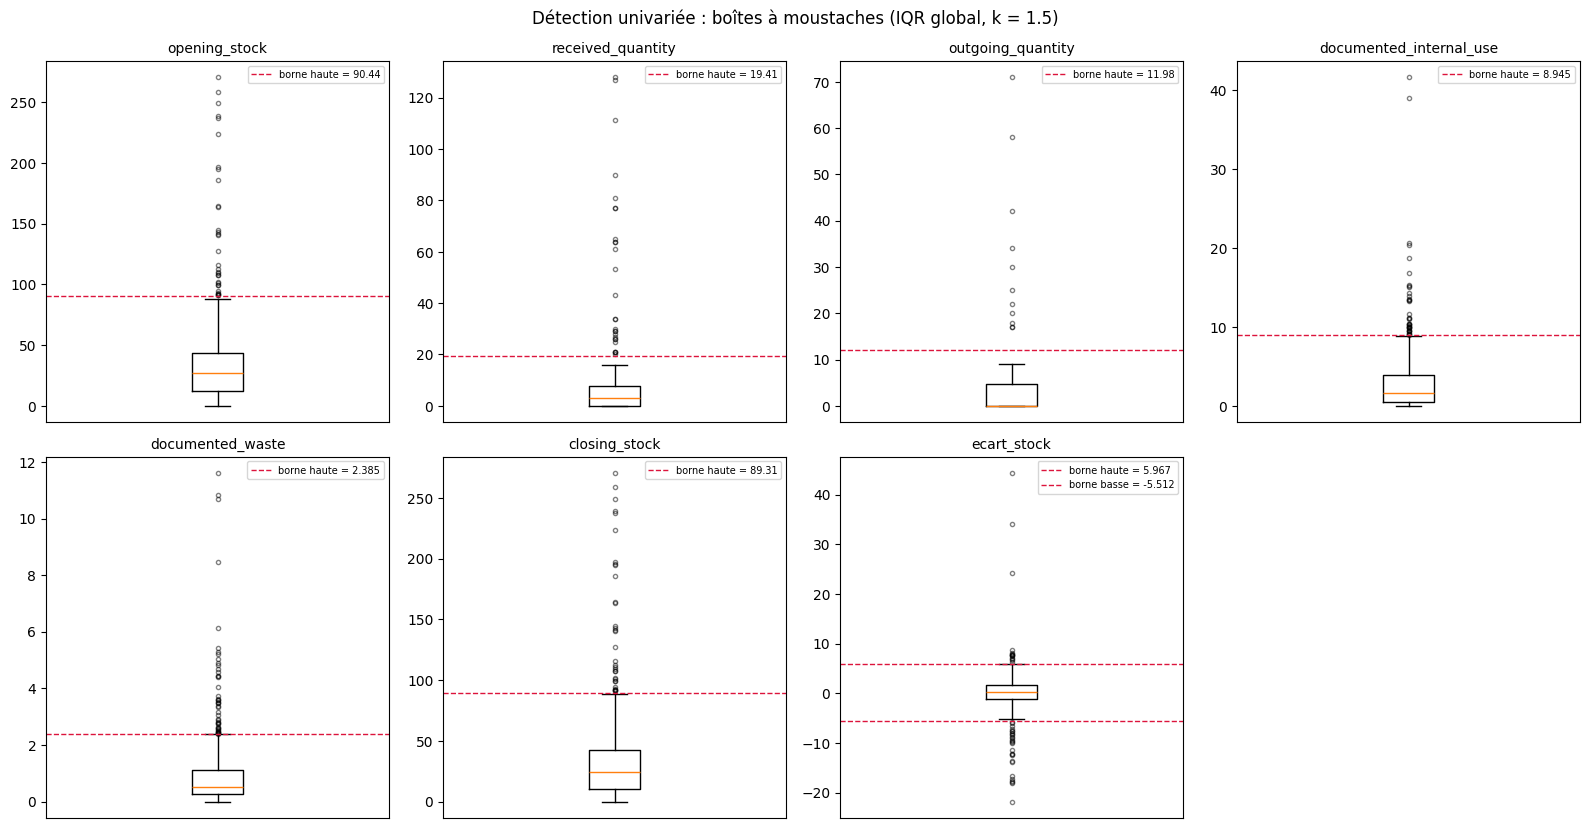

                            Q1    Q3   IQR  borne basse  borne haute  atypiques (IQR global)
variable                                                                                    
opening_stock            12.24 43.52 31.28       -34.68        90.44                      32
received_quantity            0 7.763 7.763       -11.64        19.41                      27
outgoing_quantity            0  4.79  4.79       -7.185        11.98                      11
documented_internal_use 0.5075 3.882 3.375       -4.555        8.945                      37
documented_waste          0.26  1.11  0.85       -1.015        2.385                      46
closing_stock            10.75 42.17 31.43       -36.39        89.31                      33
ecart_stock             -1.207 1.662  2.87       -5.512        5.967                      41

=== 2. Détection multivariée par regroupement ===


c:\Users\TRETEC\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Le fichier spécifié est introuvable
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\TRETEC\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\TRETEC\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 556, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\TRETEC\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 1038, 

K-means : k = 3 (silhouette 0.70), seuil de distance = 3.43 -> 34 atypiques
DBSCAN  : eps = 2.41, min_samples = 5 -> 1 groupes, 20 points bruit

=== 3. Angle-based Outlier Detection (ABOD) ===
ABOD    : FastABOD (k = 20), 3% d'ABOF les plus bas (seuil = 0.0005625) -> 15 atypiques


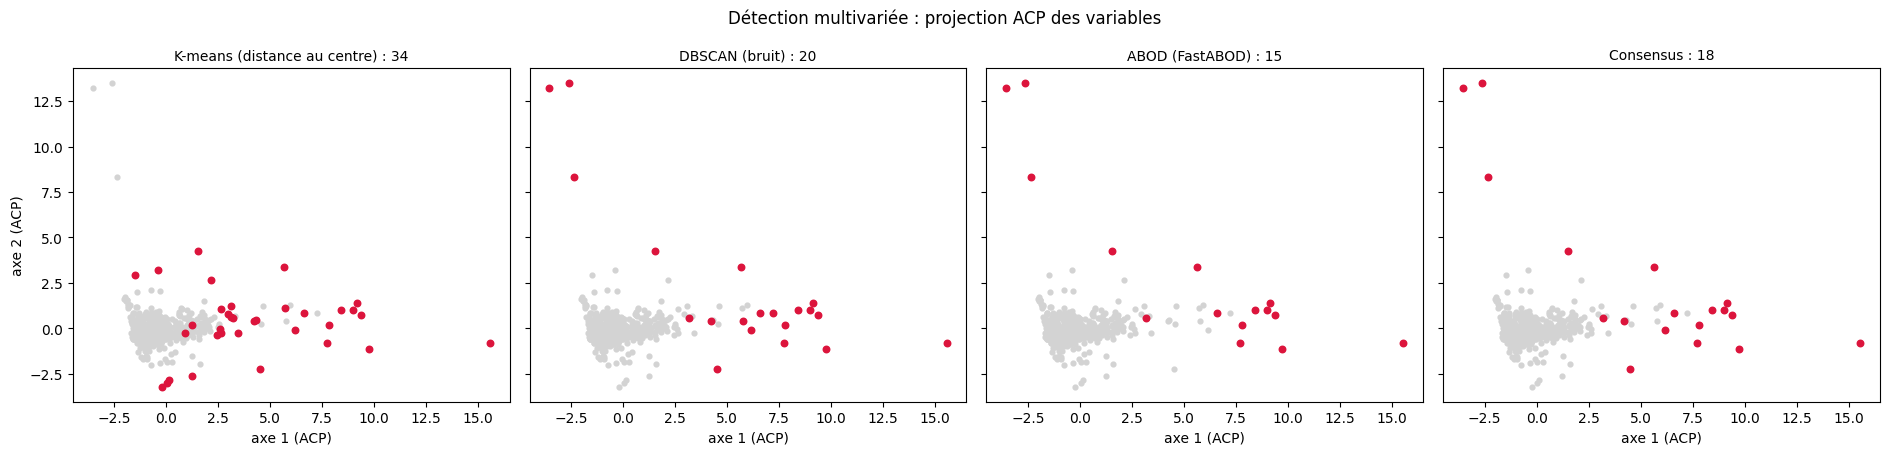


=== 4. Synthèse ===
Lignes signalées : {'out_kmeans': 34, 'out_dbscan': 20, 'out_abod': 15}
Nombre de méthodes d'accord : {0: 461, 1: 21, 2: 6, 3: 12}
Lignes en consensus (>= 2 méthodes) : 18
Lignes avec au moins une valeur hors IQR : 125


In [11]:
# Série = un couple (site, catégorie) : 25 séries de 20 mois
inv["serie"] = inv.facility_code + " | " + inv.item_category
variables = ["opening_stock", "received_quantity", "outgoing_quantity", "documented_internal_use",
             "documented_waste", "closing_stock", "ecart_stock"]

# A) Détection globale : toutes les lignes sont comparées entre elles
resultat_global = detecter_anomalies(df=inv, colonnes=variables, show=True, contamination=0.03, min_methodes=2)

In [12]:
cols = ["facility_code", "item_category", "reporting_month", "opening_stock", "received_quantity",
        "outgoing_quantity", "closing_stock", "ecart_stock", "inventory_status", "n_methodes"]
resultat_global.anomalies[cols].reset_index(drop=True)

,facility_code,item_category,reporting_month,opening_stock,received_quantity,outgoing_quantity,closing_stock,ecart_stock,inventory_status,n_methodes
0,FCL-1010,medical_consumables,2019-11-01,127.72,128.00,0.00,239.01,-3.35,closed,3
1,FCL-1010,medical_consumables,2020-04-01,239.01,5.21,0.15,223.75,-2.47,closed,3
2,FCL-1010,medical_consumables,2020-06-01,223.75,3.02,0.00,197.09,-3.64,closed,3
3,FCL-1010,medical_consumables,2022-10-01,194.88,11.14,22.00,163.80,1.68,closed,3
4,FCL-1010,medical_consumables,2023-09-01,163.80,111.41,1.91,258.70,-0.66,closed,3
5,FCL-1010,medical_consumables,2023-11-01,258.70,81.00,0.70,270.62,-17.76,revised,3
6,FCL-1010,medical_consumables,2024-05-01,249.10,0.00,0.00,237.31,0.53,closed,3
7,FCL-1010,medical_consumables,2024-03-01,270.62,11.81,5.80,249.10,-2.58,closed,3
8,FCL-1010,medical_consumables,2024-08-01,237.31,7.53,1.56,185.89,-13.64,closed,3
9,FCL-1010,medical_consumables,2025-04-01,185.89,0.00,3.15,145.00,-13.93,revised,3


### 5.2 Détection par série (chaque ligne comparée aux autres mois du même site et de la même catégorie)

*Dans `anomaly_detection`, l'option `group_by` calcule l'IQR **à l'intérieur de chaque groupe** et exprime les variables du multivarié par rapport à la médiane du groupe. Ici, la série est le couple (site, catégorie) : 25 séries de 20 relevés.*

Variables utilisées (7) : ['opening_stock', 'received_quantity', 'outgoing_quantity', 'documented_internal_use', 'documented_waste', 'closing_stock', 'ecart_stock']

=== 1. Détection univariée (IQR) ===


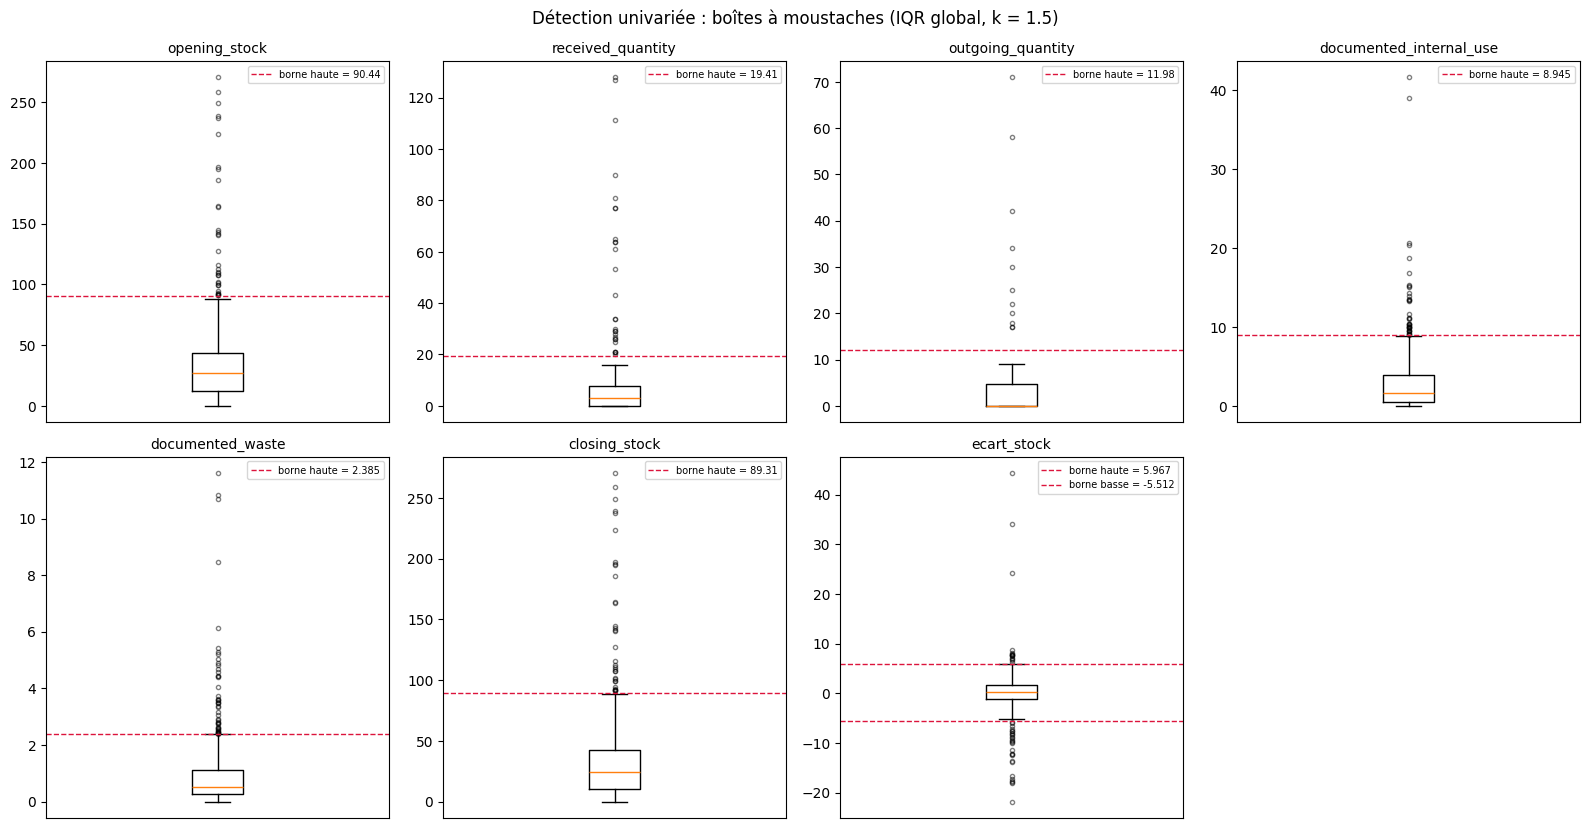

                            Q1    Q3   IQR  borne basse  borne haute  atypiques (IQR global)  atypiques (IQR par groupe)
variable                                                                                                                
opening_stock            12.24 43.52 31.28       -34.68        90.44                      32                          13
received_quantity            0 7.763 7.763       -11.64        19.41                      27                          16
outgoing_quantity            0  4.79  4.79       -7.185        11.98                      11                          23
documented_internal_use 0.5075 3.882 3.375       -4.555        8.945                      37                          26
documented_waste          0.26  1.11  0.85       -1.015        2.385                      46                          17
closing_stock            10.75 42.17 31.43       -36.39        89.31                      33                          11
ecart_stock             -1.207 1

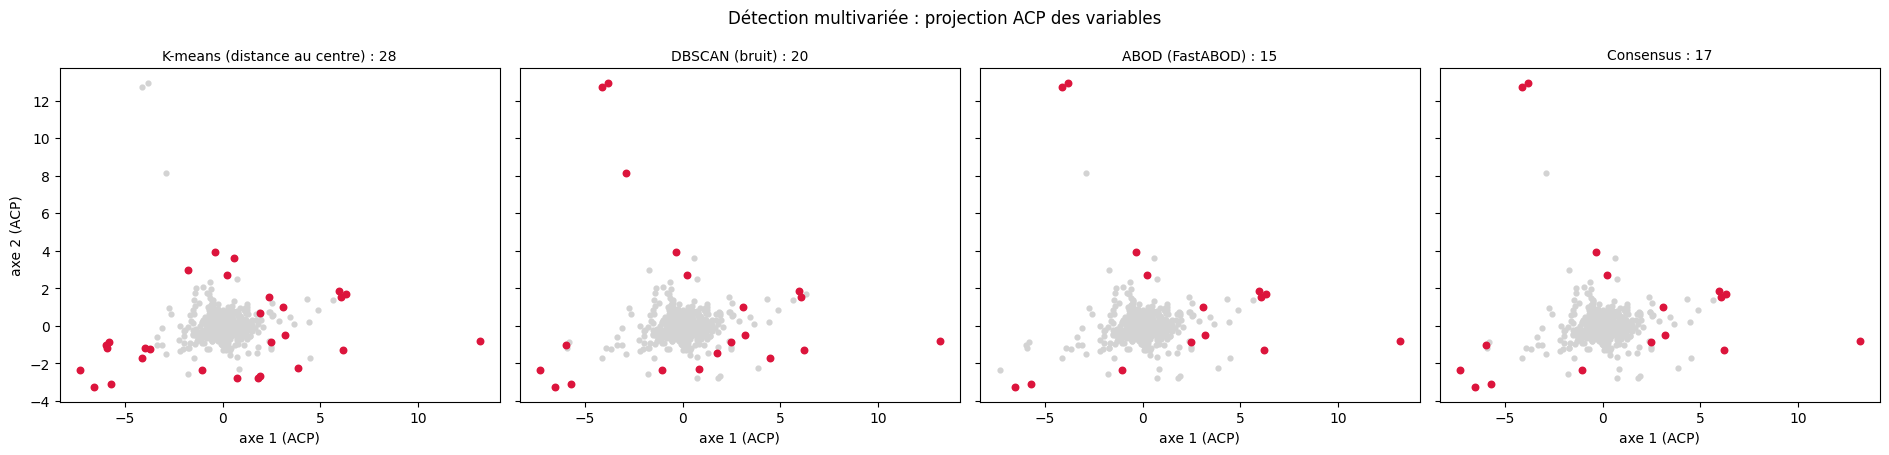


=== 4. Synthèse ===
Lignes signalées : {'out_kmeans': 28, 'out_dbscan': 20, 'out_abod': 15}
Nombre de méthodes d'accord : {0: 466, 1: 17, 2: 5, 3: 12}
Lignes en consensus (>= 2 méthodes) : 17
Lignes avec au moins une valeur hors IQR : 103


In [13]:
# B) Détection par série : chaque ligne est comparée aux autres mois du même site et de la même catégorie
resultat = detecter_anomalies(df=inv, colonnes=variables, group_by="serie", show=True,
                              contamination=0.03, min_methodes=2)

In [14]:
resultat.anomalies[cols].reset_index(drop=True)

,facility_code,item_category,reporting_month,opening_stock,received_quantity,outgoing_quantity,closing_stock,ecart_stock,inventory_status,n_methodes
0,FCL-1010,medical_consumables,2019-08-01,70.38,0.00,0.86,48.04,-12.32,closed,3
1,FCL-1020,protective_equipment,2019-08-01,21.38,127.00,4.46,141.61,0.07,closed,3
2,FCL-1010,medical_consumables,2019-09-01,48.04,90.00,0.00,127.72,-1.53,closed,3
3,FCL-1010,medical_consumables,2020-04-01,239.01,5.21,0.15,223.75,-2.47,closed,3
4,FCL-1010,medical_consumables,2020-06-01,223.75,3.02,0.00,197.09,-3.64,closed,3
5,FCL-1010,medical_consumables,2023-09-01,163.80,111.41,1.91,258.70,-0.66,closed,3
6,FCL-1010,medical_consumables,2022-10-01,194.88,11.14,22.00,163.80,1.68,closed,3
7,FCL-1010,medical_consumables,2023-11-01,258.70,81.00,0.70,270.62,-17.76,revised,3
8,FCL-1010,medical_consumables,2024-05-01,249.10,0.00,0.00,237.31,0.53,closed,3
9,FCL-1010,medical_consumables,2025-04-01,185.89,0.00,3.15,145.00,-13.93,revised,3


### 5.3 Lecture des écarts de stock



In [15]:
# Lecture des écarts de stock : d'où viennent les gains forts (> 5) et les pertes fortes (< -5) ?
inv["stock_theorique"] = (inv.opening_stock + inv.received_quantity - inv.outgoing_quantity
                          - inv.documented_internal_use - inv.documented_waste)

gains = inv[inv.ecart_classe.str.startswith("gain")]
print(f"Gains forts : {len(gains)} lignes | stock théorique négatif (sorties > stock disponible) : "
      f"{int((gains.stock_theorique < 0).sum())} | stock final enregistré = 0 : {int((gains.closing_stock == 0).sum())}")
print(gains.loc[gains.stock_theorique < 0, ["facility_code", "item_category", "reporting_month", "opening_stock",
      "received_quantity", "outgoing_quantity", "stock_theorique", "closing_stock", "ecart_stock"]].to_string(index=False, float_format="{:.2f}".format))

print("\nStatut d'inventaire x classe d'écart :")
tab = pd.crosstab(inv.inventory_status, inv.ecart_classe, margins=True)
print(tab.to_string())
pertes = inv[inv.ecart_classe.str.startswith("perte")]
print(f"\nPertes fortes : {len(pertes)} lignes dont {int((pertes.inventory_status == 'revised').sum())} au statut revised "
      f"(les lignes revised représentent {100 * (inv.inventory_status == 'revised').mean():.1f} % de la table)")
print("\nÉcart cumulé par série (les 6 plus négatives) :")
print(inv.groupby(["facility_code", "item_category"]).ecart_stock.agg(n="count", somme="sum", minimum="min")
      .round(1).sort_values("somme").head(6).to_string())

Gains forts : 19 lignes | stock théorique négatif (sorties > stock disponible) : 14 | stock final enregistré = 0 : 14
facility_code        item_category reporting_month  opening_stock  received_quantity  outgoing_quantity  stock_theorique  closing_stock  ecart_stock
     FCL-1010 protective_equipment      2022-02-01           7.57               6.17              58.00           -44.37           0.00        44.37
     FCL-1010 protective_equipment      2023-09-01           3.61               0.00               8.60            -5.28           0.00         5.28
     FCL-1010 protective_equipment      2025-06-01           0.00               0.00               7.62            -7.77           0.00         7.77
     FCL-1019 agricultural_product      2023-09-01           0.71               0.00               8.22            -7.75           0.00         7.75
     FCL-1020 agricultural_product      2023-09-01          38.01               0.00              71.00           -34.15           0.00  

### Rapport d'analyse — anomalies

**1. Détection globale (5.1)**
- IQR global : de **11** (sorties) à **46** (pertes documentées) valeurs atypiques par variable ; **125 lignes (25 %)** ont au moins une valeur hors IQR. Pour les entrées, les sorties et les pertes, Q1 = 0 (beaucoup de zéros) : la borne basse est négative et toute valeur non nulle un peu élevée est signalée, ce qui rend l'IQR peu discriminant.
- Multivarié : K-means k = 3 (silhouette **0,70**, groupes bien séparés) → 34 atypiques ; DBSCAN (ε = 2,41, un seul groupe dense) → 20 points « bruit » ; ABOD (k = 20) → 15, nombre fixé par la contamination (3 % de 500).
- Accord : aucune méthode 461 lignes, une 21, deux 6, trois **12** ; **18 lignes en consensus (3,6 %)**.

**2. Détection par série (5.2)**
- IQR par série : de 11 à 34 atypiques par variable ; **103 lignes (21 %)** avec au moins une valeur hors IQR. K-means k = 4 (silhouette 0,54) → 28 atypiques ; DBSCAN → 20 ; ABOD → 15.
- Accord : aucune 466, une 17, deux 5, trois **12** ; **17 lignes en consensus**, dont **13 communes** avec la détection globale. Comparer à la série plutôt qu'à l'ensemble ne change donc **presque rien** : les anomalies sont des anomalies *au sein* de leur série.

**3. Lecture des lignes en consensus (globale)**

| Groupe | Lignes | Description |
|---|---|---|
| **Constitution d'un gros stock** | 11 lignes de `FCL-1010` / `medical_consumables` | Le stock passe de 40 (février 2018) à **270,62** (novembre 2023) grâce à de grosses entrées (90, 128, 77, 111, 81), puis diminue. Consommation interne jusqu'à 41,59 et pertes jusqu'à 11,6. 4 de ces lignes ont un **écart négatif fort** (de −11,3 à −17,8), dont 3 sont `revised`. |
| **Gros mouvements d'équipements** | 3 lignes de `FCL-1020` / `protective_equipment` | 127 reçus (août 2019), 34 sortis (avril 2020), 77 reçus (octobre 2022) : tous à l'équilibre (écart ≈ 0). |
| **Sorties supérieures au stock** | 3 lignes : `FCL-1010` protective (février 2022), `FCL-1020` agricultural (septembre 2023) et medical (février 2022) | Écarts de **+44,37**, **+34,15** et **+24,17** : voir ci-dessous. |
| **Perte forte isolée** | 1 ligne de `FCL-1019` / `monitoring_equipment` (mai 2024) | −16,69, statut `revised`. |

**4. Écarts de stock (5.3)**
- **Les gains forts ne sont pas de vrais gains.** Sur 19 gains forts, **14 correspondent à des sorties supérieures au stock disponible** : le stock théorique est négatif et le stock final est enregistré à 0. Les trois plus grands : `FCL-1010` protective_equipment (ouverture 7,57 + 6,17 reçus − **58 sortis** = −44,37 → clôture 0), `FCL-1020` agricultural_product (38,01 − **71** = −34,15) et `FCL-1020` medical_consumables (18,69 − **42** = −24,17). Ces trois sorties coïncident avec des expéditions de la table `shipments` (étape 4.3) : **des quantités ont été expédiées alors que le stock enregistré était insuffisant** (ou le stock a été mal enregistré). Dans ces 14 cas, le stock final est enregistré à 0 : un stock négatif est ramené à zéro, ce qui fabrique un « gain » artificiel.
- **Les pertes fortes sont, elles, concentrées sur le statut `revised`.** Sur 28 pertes fortes (< −5), **13 sont `revised`**, alors que les lignes `revised` ne représentent que **3,6 %** de la table. À l'inverse, **13 des 18 lignes `revised` (72 %)** ont une perte forte, contre 14 sur 444 (3 %) pour les lignes `closed` (V de Cramér de 0,39). Aucune ligne `revised` n'est un gain fort.
- **Écart cumulé par série** : `FCL-1010` medical_consumables **−82,2** (20 lignes, minimum −17,8), `FCL-1019` biological_sample −42,6, `FCL-1020` biological_sample −38,7, `FCL-1027` biological_sample −25,3, `FCL-1027` monitoring_equipment −22,1 et `FCL-1027` medical_consumables −16,6.

**Interprétation**
- Les anomalies statistiques (niveaux de stock inhabituels) et les **déficits** (écart de stock) sont des phénomènes **différents** : le gros stock de `FCL-1010` est signalé par les trois méthodes, mais la plupart de ses lignes sont à l'équilibre ; en revanche, les séries d'échantillons biologiques de `FCL-1019` et `FCL-1020`, déficitaires, ne figurent pas parmi les lignes en consensus : leur déficit se voit dans l'écart de stock, pas dans le niveau de stock.
- **Trois foyers de déficit** se dégagent : (1) les **échantillons biologiques liés aux expéditions « wildlife »** (`FCL-1019`, `FCL-1020`, `FCL-1024`), (2) les **consommables médicaux de `FCL-1010`**, qui cumulent le plus gros déficit et ne sont pas liés à ces expéditions, et (3) le site **`FCL-1027`**, déficitaire sur trois catégories sans mouvement rapproché des expéditions.
- Le statut `revised` marque les **inventaires corrigés** après constat d'un manque : c'est cohérent avec une révision qui ramène le stock à la réalité observée (hypothèse à confirmer).

**Points d'attention**
- Les seuils sont des choix (3 % pour l'ABOD, distance de K-means, ε de DBSCAN) et il n'y a pas de vérité terrain.
- Les lignes avec beaucoup de zéros rendent l'IQR et les ratios peu fiables ; l'**écart de stock** est la mesure la plus informative de cette table.

---
## 6. Analyse temporelle et comparaison des sites 
Les séries sont définies par le couple `facility_code × item_category`.
On examine les stocks de clôture et les écarts comptables au fil des relevés.

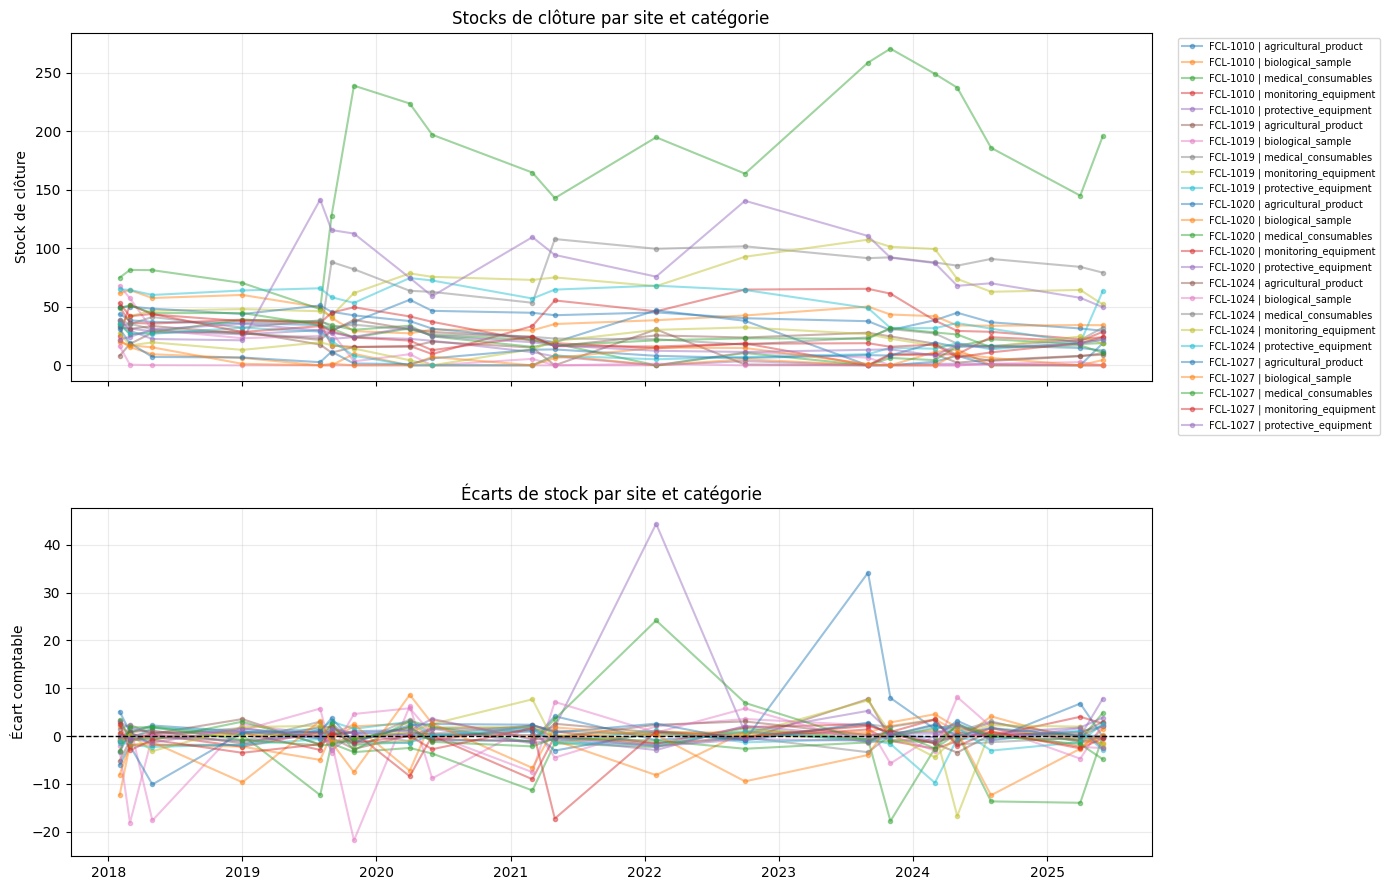

In [16]:
inv_temp = inv.copy()
inv_temp["reporting_month"] = pd.to_datetime(inv_temp["reporting_month"], errors="coerce")
inv_temp = inv_temp.dropna(subset=["reporting_month"]).sort_values(
    ["facility_code", "item_category", "reporting_month"]
)

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
for (site, categorie), g in inv_temp.groupby(["facility_code", "item_category"]):
    label = f"{site} | {categorie}"
    axes[0].plot(g["reporting_month"], g["closing_stock"],
                 marker=".", alpha=.45, label=label)
    axes[1].plot(g["reporting_month"], g["ecart_stock"],
                 marker=".", alpha=.45, label=label)

axes[0].set_title("Stocks de clôture par site et catégorie")
axes[0].set_ylabel("Stock de clôture")
axes[1].set_title("Écarts de stock par site et catégorie")
axes[1].set_ylabel("Écart comptable")
axes[1].axhline(0, linestyle="--", color="black", linewidth=1)
for ax in axes:
    ax.grid(alpha=.25)
axes[0].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)
plt.tight_layout()
plt.show()

### 6.1 Carte thermique des écarts par site et catégorie

Les codes de sites sont utilisés comme unités d'analyse spatiale indirecte.
Sans coordonnées ni voisinage géographique documenté, cette heatmap compare
des sites mais ne constitue pas une carte géographique ni un test de Moran.

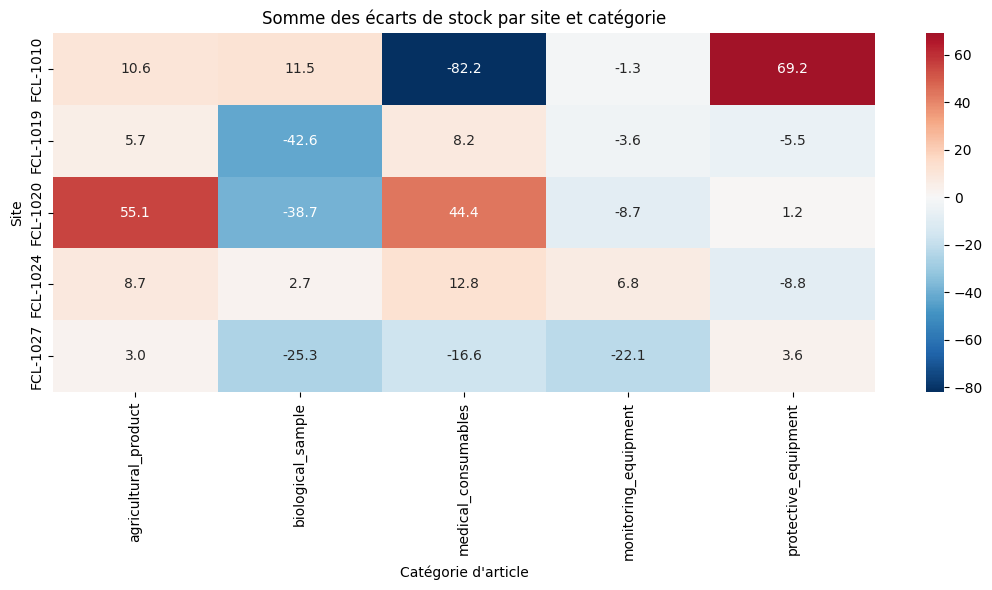

item_category,agricultural_product,biological_sample,medical_consumables,monitoring_equipment,protective_equipment
facility_code,,,,,
FCL-1010,10.56,11.54,-82.20,-1.34,69.23
FCL-1019,5.72,-42.60,8.19,-3.63,-5.52
FCL-1020,55.13,-38.67,44.36,-8.69,1.17
FCL-1024,8.74,2.71,12.83,6.75,-8.81
FCL-1027,2.95,-25.25,-16.58,-22.12,3.56


In [17]:
import seaborn as sns

matrice_ecarts = inv_temp.pivot_table(
    index="facility_code", columns="item_category",
    values="ecart_stock", aggfunc="sum"
)
plt.figure(figsize=(11, 6))
sns.heatmap(matrice_ecarts, annot=True, fmt=".1f",
            center=0, cmap="RdBu_r")
plt.title("Somme des écarts de stock par site et catégorie")
plt.xlabel("Catégorie d'article")
plt.ylabel("Site")
plt.tight_layout()
plt.show()
display(matrice_ecarts.round(2))

### 6.2 Décomposition STL : uniquement si la fréquence est régulière

STL sépare une série en tendance, saisonnalité et résidu.
Le code vérifie d'abord que les dates sont mensuelles et régulières.
Si la condition n'est pas remplie, la décomposition est ignorée plutôt
que d'interpoler silencieusement des observations.

In [18]:
from statsmodels.tsa.seasonal import STL

# Choisir une série pour l'inspection ; modifier ces deux valeurs si nécessaire.
site_exemple = inv_temp["facility_code"].iloc[0]
categorie_exemple = inv_temp["item_category"].iloc[0]

serie_stl = (
    inv_temp[(inv_temp.facility_code == site_exemple) &
             (inv_temp.item_category == categorie_exemple)]
    .set_index("reporting_month")["ecart_stock"]
    .sort_index()
)

# Une série mensuelle régulière doit avoir un index MS/M et aucune date manquante.
serie_mensuelle = serie_stl.copy()
serie_mensuelle.index = serie_mensuelle.index.to_period("M").to_timestamp()
serie_mensuelle = serie_mensuelle[~serie_mensuelle.index.duplicated(keep="first")]

index_attendu = pd.date_range(
    serie_mensuelle.index.min(), serie_mensuelle.index.max(), freq="MS"
) if len(serie_mensuelle) else pd.DatetimeIndex([])

if (len(serie_mensuelle) >= 24
    and serie_mensuelle.index.equals(index_attendu)
    and serie_mensuelle.notna().all()
    and serie_mensuelle.nunique() > 1):
    decomposition = STL(serie_mensuelle, period=12, robust=True).fit()
    fig = decomposition.plot()
    fig.set_size_inches(13, 8)
    fig.suptitle(f"STL — {site_exemple} / {categorie_exemple}", y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("STL non appliqué : il faut au moins 24 observations mensuelles "
          "consécutives, sans doublon ni valeur manquante.")
    print("Nombre d'observations :", len(serie_mensuelle),
          "| dates mensuelles attendues :", len(index_attendu))

STL non appliqué : il faut au moins 24 observations mensuelles consécutives, sans doublon ni valeur manquante.
Nombre d'observations : 20 | dates mensuelles attendues : 89


### 6.3 Détection locale des écarts inhabituels par fenêtre glissante

Pour chaque site et catégorie, on compare l'écart de stock à la médiane
locale d'une fenêtre de cinq relevés. Le score utilise le MAD (écart absolu
médian), plus robuste aux valeurs extrêmes que moyenne/écart-type.
Une fenêtre de cinq lignes correspond à cinq relevés, pas nécessairement
à cinq mois si le calendrier change.

In [19]:
def ajouter_score_local(groupe, fenetre=5):
    groupe = groupe.sort_values("reporting_month").copy()
    x = groupe["ecart_stock"].astype(float)
    med = x.rolling(fenetre, center=True, min_periods=3).median()
    mad = x.rolling(fenetre, center=True, min_periods=3).apply(
        lambda valeurs: np.median(np.abs(valeurs - np.median(valeurs))),
        raw=True
    )
    denominateur = 1.4826 * mad.replace(0, np.nan)
    groupe["score_local_mad"] = (x - med) / denominateur
    groupe["anomalie_locale"] = groupe["score_local_mad"].abs() > 3.5
    return groupe

inv_local = (
    inv_temp.groupby(["facility_code", "item_category"], group_keys=False)
    .apply(ajouter_score_local)
)
anomalies_locales = inv_local[inv_local["anomalie_locale"].fillna(False)]
display(anomalies_locales[
    ["facility_code", "item_category", "reporting_month",
     "ecart_stock", "score_local_mad"]
].sort_values("score_local_mad", key=lambda s: s.abs(), ascending=False))
print("Nombre d'anomalies locales :", len(anomalies_locales))

C:\Users\TRETEC\AppData\Local\Temp\ipykernel_1444\1532514462.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(ajouter_score_local)


,facility_code,item_category,reporting_month,ecart_stock,score_local_mad
220,FCL-1020,biological_sample,2018-02-01,-12.30,-710.238770
440,FCL-1027,medical_consumables,2018-02-01,-3.20,-113.089617
59,FCL-1010,medical_consumables,2025-06-01,-0.16,31.352191
93,FCL-1010,protective_equipment,2023-09-01,5.28,29.677593
91,FCL-1010,protective_equipment,2022-02-01,44.37,26.803128
10,FCL-1010,agricultural_product,2021-05-01,4.15,24.040778
113,FCL-1019,agricultural_product,2023-09-01,7.75,23.747695
417,FCL-1027,agricultural_product,2024-08-01,1.68,21.583704
195,FCL-1019,protective_equipment,2024-03-01,-9.75,-15.708535
176,FCL-1019,monitoring_equipment,2024-05-01,-16.69,-15.540267


Nombre d'anomalies locales : 53


### 6.4 Autocorrélation des écarts

Les retards de l'ACF correspondent à des relevés successifs. Ils ne sont
interprétables comme des mois que si les relevés sont mensuels et réguliers.

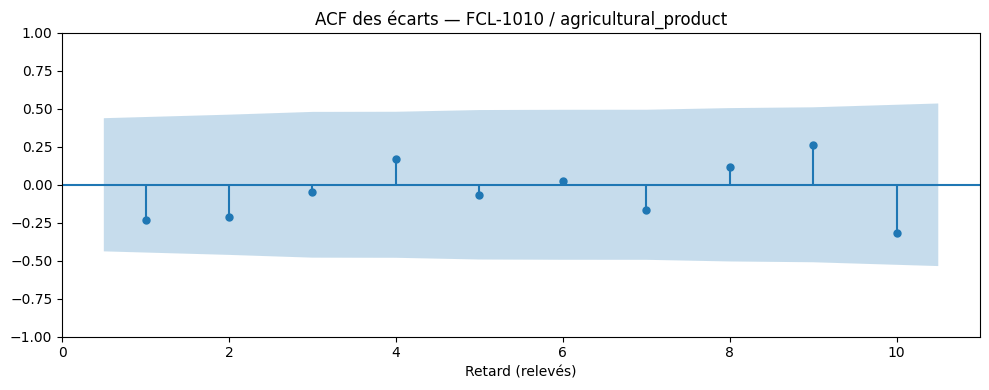

In [20]:
from statsmodels.graphics.tsaplots import plot_acf

serie_acf = (
    inv_temp[(inv_temp.facility_code == site_exemple) &
             (inv_temp.item_category == categorie_exemple)]
    .sort_values("reporting_month")["ecart_stock"]
    .dropna()
)
if len(serie_acf) >= 5 and serie_acf.nunique() > 1:
    fig, ax = plt.subplots(figsize=(10, 4))
    plot_acf(serie_acf, lags=min(10, len(serie_acf)-1),
             zero=False, ax=ax)
    ax.set_title(f"ACF des écarts — {site_exemple} / {categorie_exemple}")
    ax.set_xlabel("Retard (relevés)")
    plt.tight_layout()
    plt.show()
else:
    print("Série trop courte ou constante pour l'ACF.")

## Synthèse — Déficits de stock associés aux expéditions wildlife

Le recoupement entre les mouvements d'inventaire et les expéditions révèle une différence importante entre les opérations ordinaires et les expéditions associées au programme wildlife.

Tout d'abord, les mouvements logistiques sont globalement bien retranscrits dans l'inventaire : les quantités sorties correspondent exactement aux quantités expédiées dans les 27 cas identifiés. Pour les entrées, 31 des 36 correspondances présentent également des quantités identiques.

Cependant, les lignes d'inventaire associées aux expéditions wildlife présentent un comportement différent :

- 18 lignes sont associées à une expédition wildlife.
- 16 de ces 18 lignes présentent un écart de stock négatif.
- Le déficit cumulé atteint **−131 unités**.
- L'écart moyen est de **−7,28 unités**, contre **+0,01 unité** pour les lignes sans expédition correspondante.
- Les sites `FCL-1019` et `FCL-1020` présentent des écarts moyens particulièrement négatifs pendant les mois concernés par ces expéditions.

Le rapprochement avec les ajustements montre que les 18 expéditions wildlife sont associées à des ajustements négatifs de **−2,90 unités en moyenne**. Ces ajustements ne couvrent donc qu'une partie du déficit constaté dans l'inventaire.

Cette observation est importante : les mouvements d'expédition sont identifiables et leurs quantités sont reprises dans les mouvements de stock, mais le bilan final reste déficitaire dans la majorité des cas associés au flux wildlife.

Les analyses d'anomalies apportent une précision supplémentaire. Les déficits de stock ne correspondent pas nécessairement à des niveaux de stock statistiquement atypiques. Il faut donc distinguer les valeurs extrêmes des incohérences comptables mesurées par `ecart_stock`.

**Indice pour l'hypothèse globale :** le flux wildlife est associé à des déficits de stock récurrents qui ne sont pas entièrement expliqués par les ajustements enregistrés. Ce phénomène est concentré sur certains sites et mérite une investigation spécifique.

**Limite :** un écart négatif ne prouve pas une disparition physique de marchandises. Il peut également résulter d'une consommation non documentée, d'un décalage de période, d'une réception manquante ou d'une erreur d'enregistrement.